# BUSI: загрузка и статистика (UNI-40)

Запустите все ячейки в Google Colab и разрешите доступ к Google Drive.
Рабочая копия BUSI находится в `My Drive/colab/data/busi`.
Данные копируются в локальную среду Colab; GPU не требуется.

Показываем распределение классов, размеры, каналы и примеры изображений.
Маски исключаем из статистики классификации по имени файла согласно
[плану экспериментов](https://github.com/carbon77/breast-cancer-classification/blob/main/docs/baseline-experiment-plan.md).
Проверки папок, формата, целостности, масок и дубликатов не выполняются.
Split и обучение выполняются отдельно.


In [1]:
from pathlib import Path
import shutil

import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
from IPython.display import display
from PIL import Image

# Порядок классов соответствует документации проекта.
CLASSES = ("normal", "benign", "malignant")
DRIVE_ROOT = Path("/content/drive/MyDrive/colab/data/busi")
DATA_ROOT = Path("/content/busi")


## Загрузка из Google Drive

Исходные файлы на Drive остаются без изменений. Локальная копия доступна
до завершения сессии Colab. Повторный запуск копирования обновляет файлы.


In [2]:
drive.mount("/content/drive")
shutil.copytree(DRIVE_ROOT, DATA_ROOT, dirs_exist_ok=True)
print(f"Датасет скопирован в {DATA_ROOT}")


Mounted at /content/drive
Датасет скопирован в /content/busi


## Статистика исходных изображений

Берём PNG из трёх папок классов, исключая имена с `_mask`.
Размеры и число каналов читаем без преобразования изображений.


,images,share_percent
class,,
normal,133,17.05
benign,437,56.03
malignant,210,26.92


Всего исходных изображений: 780


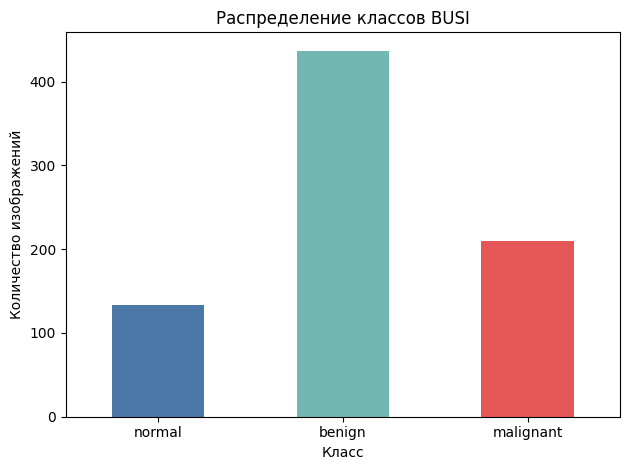

In [3]:
records = []
for class_name in CLASSES:
    for path in sorted((DATA_ROOT / class_name).glob("*.png")):
        # Ground-truth маски не являются примерами для классификации.
        if "_mask" in path.stem.lower():
            continue
        with Image.open(path) as image:
            records.append({
                "class": class_name,
                "filepath": path.relative_to(DATA_ROOT).as_posix(),
                "width": image.width,
                "height": image.height,
                "channels": len(image.getbands()),
                "mode": image.mode,
            })

images = pd.DataFrame(records)
counts = images.groupby("class").size().reindex(CLASSES, fill_value=0)
summary = counts.rename("images").to_frame()
summary["share_percent"] = (100 * counts / counts.sum()).round(2)
display(summary)
print(f"Всего исходных изображений: {len(images)}")

ax = counts.plot.bar(color=["#4c78a8", "#72b7b2", "#e45756"], rot=0)
ax.set(title="Распределение классов BUSI", xlabel="Класс", ylabel="Количество изображений")
plt.tight_layout()
plt.show()


Размеры и число каналов по классам:


width              height             channels           
            min median   max    min median  max      min median max
class                                                              
normal      391  616.0   948    310  493.0  712        3    3.0   3
benign      315  563.0  1028    324  471.0  719        3    3.0   3
malignant   190  564.0  1048    332  474.0  677        3    3.0   3

Распределение по режимам и числу каналов:


mode,RGB
channels,3
class,
normal,133
benign,437
malignant,210


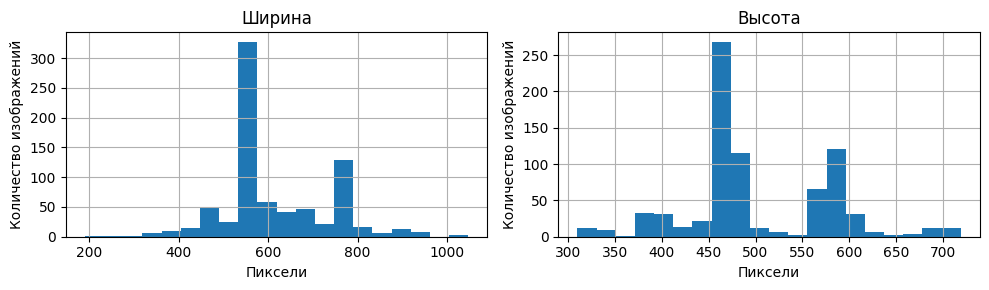

In [4]:
print("Размеры и число каналов по классам:")
display(
    images.groupby("class")[["width", "height", "channels"]]
    .agg(["min", "median", "max"])
    .reindex(CLASSES)
)
print("Распределение по режимам и числу каналов:")
display(pd.crosstab(images["class"], [images["mode"], images["channels"]]).reindex(CLASSES, fill_value=0))

axes = images[["width", "height"]].hist(bins=20, figsize=(10, 3))
for ax, title in zip(axes.flat, ("Ширина", "Высота")):
    ax.set(title=title, xlabel="Пиксели", ylabel="Количество изображений")
plt.tight_layout()
plt.show()


## Примеры изображений

Первые три изображения каждого класса в порядке имён файлов.
Показаны исходные снимки без масок и изменения размеров.


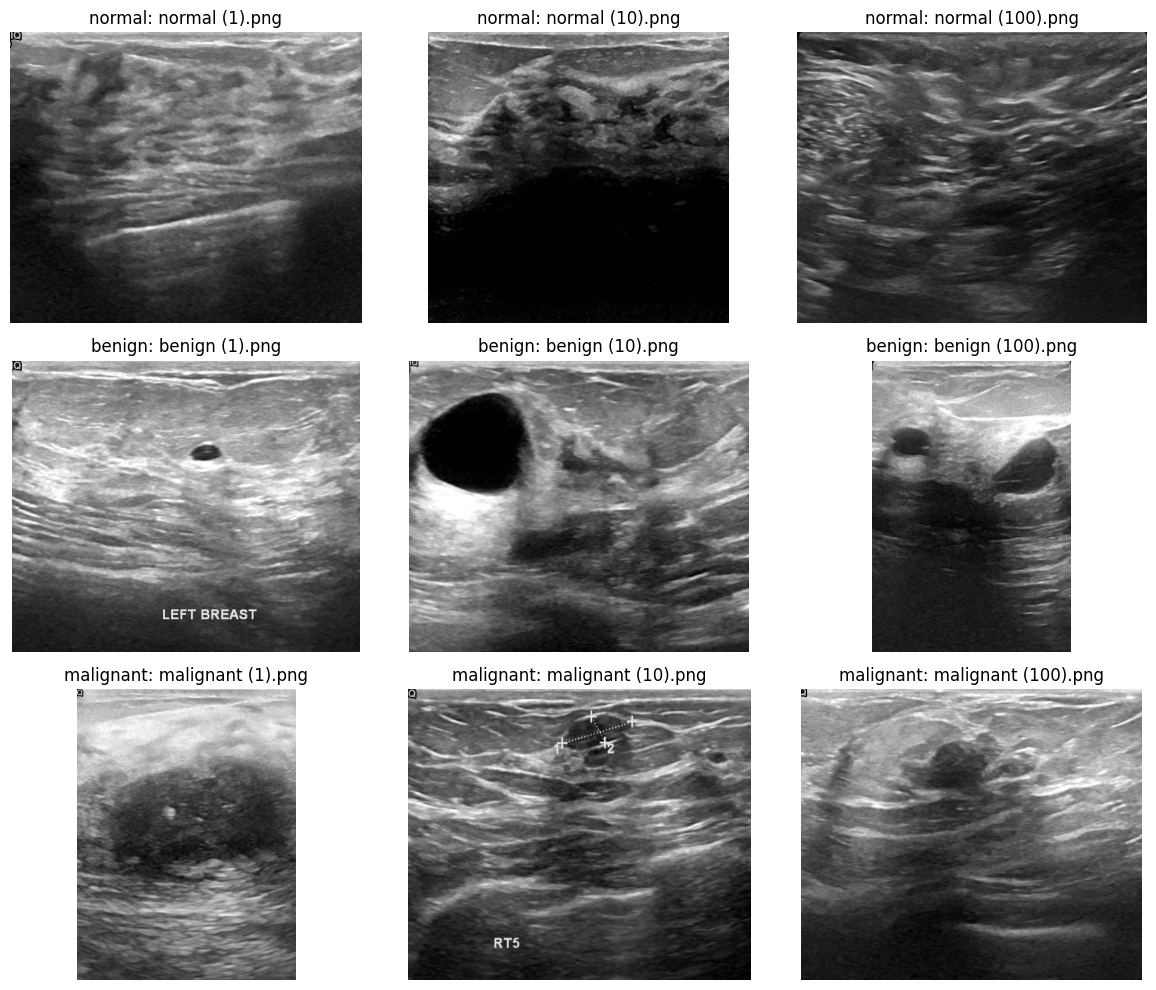

In [5]:
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(12, 10))
for row, class_name in enumerate(CLASSES):
    paths = images.loc[images["class"] == class_name, "filepath"].head(3)
    for ax in axes[row]:
        ax.axis("off")
    for ax, filepath in zip(axes[row], paths):
        with Image.open(DATA_ROOT / filepath) as image:
            ax.imshow(image, cmap="gray")
        ax.set_title(f"{class_name}: {Path(filepath).name}")
plt.tight_layout()
plt.show()


Результаты остаются в выводах ноутбука. После выполнения сохраните его
копию с выводами через меню Colab, если нужна фактическая статистика в отчёте.
